# M05-2 | Calibration: How Sample Count Affects Results, and Does BN Move During Calibration

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m05_ptq_pipeline/02_calibration_study.ipynb)

Calibration data determines the range each observer sees, and therefore the scale. With too little data the range is poorly estimated. This notebook uses the output SQNR from M05-1 to measure two things:

- **A.** Calibration sample count vs SQNR: for each sample count, use 5 different calibration sets, run once each, and look at the mean and the **spread**.
- **B.** Whether BN affects results during calibration.

In [1]:
#| include: false
# When running on Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # lets the notebook import this course's common/
    os.chdir(f"{repo}/en/m05_ptq_pipeline")

In [2]:
import copy

import matplotlib.pyplot as plt
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats

from common.data import calibration_batches, trained_tiny_net
from common.graph_utils import sqnr
from common.models import example_inputs
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import table

quiet()
_ = torch.manual_seed(0)
set_matplotlib_formats("svg")
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"

Model and evaluation data are the same as in M05-1 (`trained_tiny_net()`, `calibration_batches(64, seed=9)`):

In [3]:
model = trained_tiny_net()
gm = export_module(model, example_inputs())
quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)
(x_eval,) = next(calibration_batches(64, seed=9))  # fixed evaluation input, different from all calibration sets
with torch.no_grad():
    y_ref = model(x_eval)

## A. Calibration Sample Count vs SQNR

For each sample count $n$, generate 5 calibration sets with 5 different seeds, and do prepare, calibration, and convert once for each:

In [4]:
SEEDS = (1, 2, 3, 4, 5)
SIZES = (16, 32, 64, 128, 256, 512)

results = {}
for n in SIZES:
    results[n] = []
    for seed in SEEDS:
        prepared = prepare_pt2e(copy.deepcopy(gm), quantizer)
        with torch.no_grad():
            for batch in calibration_batches(n, seed=seed):
                prepared(*batch)
            results[n].append(sqnr(y_ref, convert_pt2e(prepared)(x_eval)))

mean = {n: sum(v) / len(v) for n, v in results.items()}
spread = {n: max(v) - min(v) for n, v in results.items()}

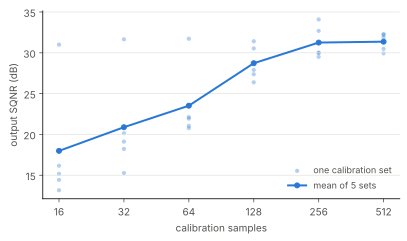

In [5]:
#| code-fold: true
#| code-summary: Plotting code
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for i, (n, scores) in enumerate(results.items()):
    ax.scatter([n] * len(scores), scores, s=18, color=BLUE, alpha=0.35, linewidths=0,
               label="one calibration set" if i == 0 else None)
ax.plot(SIZES, [mean[n] for n in SIZES], color=BLUE, lw=2, marker="o", ms=5, label="mean of 5 sets")
ax.legend(loc="lower right", frameon=False, labelcolor=MUTED, fontsize=9)
ax.set_xscale("log", base=2)
ax.set_xticks(SIZES, [str(n) for n in SIZES])
ax.set_xlabel("calibration samples", color=MUTED)
ax.set_ylabel("output SQNR (dB)", color=MUTED)
ax.grid(axis="y", color="#e6e5e1", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
plt.show()

In [6]:
table([[n, f"{mean[n]:.2f}", f"{min(results[n]):.2f} ~ {max(results[n]):.2f}", f"{spread[n]:.2f}"] for n in SIZES],
      ["calibration samples", "mean", "min ~ max", "spread (max − min)"])

calibration samples,mean,min ~ max,spread (max − min)
16,17.99,13.17 ~ 31.00,17.84
32,20.89,15.28 ~ 31.66,16.38
64,23.52,20.77 ~ 31.72,10.96
128,28.73,26.39 ~ 31.42,5.03
256,31.26,29.50 ~ 34.08,4.58
512,31.36,29.93 ~ 32.28,2.35


In [7]:
assert spread[SIZES[0]] > 2 * spread[SIZES[-1]]  # the spread is much larger with few samples
assert mean[SIZES[0]] < mean[SIZES[-1]]

Each light dot in the plot is the result of one calibration set; the dark line is the mean of the 5:
- With few samples, not only is the mean lower, but more importantly **the result differs a lot from one calibration set to the next**. Same model, same setting, and SQNR can differ by more than ten dB just because the calibration data differs.
- With more samples, the dots tighten up. So what to look at is the spread, not a single run: running once and happening to draw a good set overestimates the quantization quality.
- This synthetic data is i.i.d. and very clean; how many samples real data needs depends on the data itself, and these numbers cannot be applied directly.

In practice: increase the sample count until the spread converges; when you suspect the quantization quality, first rerun with a few different calibration sets and see whether the results are stable.

## B. Does BN Affect Results During Calibration

As seen in M04-1, `prepare_pt2e` folds BN into conv right at the start. So the graph used for calibration already has no BN:

In [8]:
prepared = prepare_pt2e(copy.deepcopy(gm), quantizer)
n_bn = sum("batch_norm" in str(n.target) for n in prepared.graph.nodes)
print("number of batch_norm nodes after prepare:", n_bn)
assert n_bn == 0

number of batch_norm nodes after prepare: 0


What difference does this make? Compare the output of the same sample "run alone" and "run together with 15 other samples in the same batch".
The control group is the original model in train mode: BN uses the current batch's statistics, so the output changes with the other samples in the batch.

In [9]:
(x,) = next(calibration_batches(16, seed=5))
bn_train = copy.deepcopy(model).train()
with torch.no_grad():
    alone = torch.cat([prepared(x[i : i + 1]) for i in range(len(x))])
    together = prepared(x)
    bn_alone = torch.cat([bn_train(x[i : i + 1]) for i in range(len(x))])
    bn_together = bn_train(x)
d_prepared = float((alone - together).abs().max())
d_bn = float((bn_alone - bn_together).abs().max())
table([["graph after prepare (used for calibration)", f"{d_prepared:.2e}"], ["control: original model in train mode", f"{d_bn:.2e}"]],
      ["", "run alone vs with 15 others in the same batch: max output difference"])

,run alone vs with 15 others in the same batch: max output difference
graph after prepare (used for calibration),4.40e-06
control: original model in train mode,6.79e+00


In [10]:
assert d_prepared < 1e-3 < d_bn

- In the calibration graph, BN is already a fixed multiply-add (folded into conv using the running stats), and this model has no other cross-batch ops, so the output depends only on the sample itself and the difference is only floating-point error.
- The control group's output changes with the other samples in the batch. If BN worked like this during calibration, the range the observer sees would drift with the batch composition. The PTQ graph has no BN, so it naturally avoids this problem (provided export used eval mode).

So during PTQ calibration you need not worry about BN; for this model, the calibration batch size only affects how fast it runs. Only QAT has the BN statistics problem (M06).

## Summary

- With few calibration samples, results vary a lot with the calibration data; look at the spread, not just a single run.
- The graph used for PTQ calibration has no BN, so the output is not affected by batch composition.